In [359]:
df = pd.read_csv("~/Documents/nonstat/topo_nu_neural.csv", header=None, names=['Res', 'Lat', 'Lon'])
df.describe()

,Res,Lat,Lon
count,4576.000000,4576.000000,4576.000000
mean,0.679478,-100.927961,39.766927
std,0.365726,15.138862,5.264082
min,0.003152,-125.533300,24.555000
25%,0.352461,-113.995627,35.745830
50%,0.896396,-102.801550,40.200000
75%,0.989811,-88.387375,43.994000
max,0.999940,-64.916700,52.966700


In [518]:
import altair as alt
from altair.datasets import data
import pandas as pd
import numpy as np

# df = pd.read_csv("~/Documents/nonstat/topo_var_neural2.csv", header=None, names=['Res', 'Lon', 'Lat'])
# df = pd.read_csv("~/Documents/nonstat/topo_var_basis.csv", header=None, names=['Res', 'Lon', 'Lat'])
df = pd.read_csv("/Users/zj/Documents/nonstat/predictions_topo_neural.csv", header=None, names=['Res', 'Lon', 'Lat'])
# df = pd.read_csv("~/Documents/nonstat/topo_nu_basis.csv", header=None, names=['Res', 'Lon', 'Lat'])
df['Res'] = np.sqrt(df['Res'])  # Take absolute value for color mapping


# Load US states from topojson
states = alt.topo_feature(data.us_10m.url, feature='states')

# US states background
background = alt.Chart(states).mark_geoshape(
    fill='lightgray',
    stroke='white'
).properties(
    width=700,
    height=500
).project('albersUsa')

# Create points using your CSV data with improved legend
points = alt.Chart(df).mark_circle(
    size=20,  # Fixed size of 20
    opacity=0.8
).encode(
    longitude='Lon:Q',
    latitude='Lat:Q',
    color=alt.Color('Res:Q', 
                #    scale=alt.Scale(scheme='redblue', reverse=True, domain=[-7, 7]),
                   scale=alt.Scale(scheme='reds', domain=[0, 3]),
                #    title='Temperature Deviation (°C)',
                title='Estimated Noise Std. Dev.',
                   legend=alt.Legend(
                       orient='bottom',  # Place legend at bottom
                       direction='horizontal',  # Horizontal legend
                       titleFontSize=14,
                       labelFontSize=12,
                       titlePadding=10,
                       gradientLength=300,
                       gradientThickness=15
                   ))
    # tooltip=['Lon:Q', 'Lat:Q', 'Res:Q']
).project('albersUsa')

# Combine background and points
final_plot = background + points

# Display the plot
final_plot

alt.LayerChart(...)

In [111]:
final_plot.save('topo_neural.png', scale_factor=2.0)

In [2]:
# Cell 1: Import libraries and load global dataset
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import pandas as pd
import numpy as np

# Load the global dataset
# df_global = pd.read_csv("~/Documents/nonstat/braceu.csv")
df_global = pd.read_csv("/Users/zj/Documents/GpGpUPaper/jason3_noland.csv")
# df_global = pd.read_csv("~/Documents/nonstat/basis_values.csv", header=None)#, names=['Res', 'Lon', 'Lat'])
# df_global = df_global.iloc[:,[0,1,10]]
df_global = df_global.iloc[:,[1,0,5]]
df_global.columns = ['Lon', 'Lat', 'res']

print(f"Loaded dataset with {len(df_global):,} points")
print(f"Columns: {list(df_global.columns)}")
print(f"Data preview:")
print(df_global.head())

Loaded dataset with 1,040,815 points
Columns: ['Lon', 'Lat', 'res']
Data preview:
         Lon        Lat    res
0  56.162758 -59.760163  12.50
1  56.733110 -59.532837  14.79
2  57.375068 -59.269707  16.63
3  58.006621 -59.003114  15.81
4  58.627908 -58.733145  16.43


In [195]:
knots_df = pd.read_csv('~/Documents/nonstat/knots.csv')
knots_df.columns = ['Lat', 'Lon']
knots_df.head()


,Lat,Lon
0,87.707557,137.507764
1,86.757780,-84.984472
2,86.028843,52.523292
3,85.414197,-169.968944
4,84.872574,-32.461180


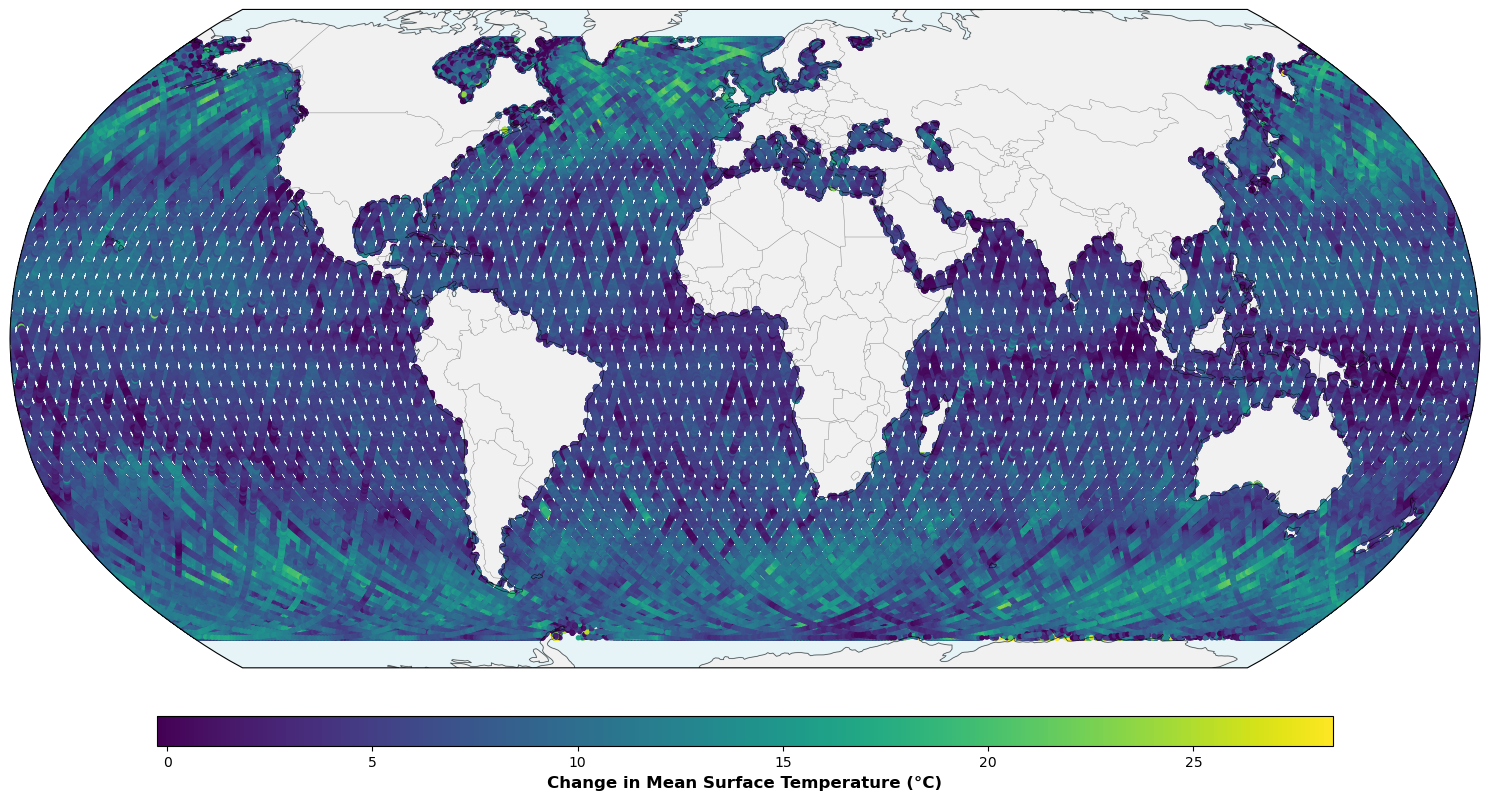

In [19]:
# Cell 2: Create map, plot data, and format
# Create figure with Robinson projection (great for global views)
fig = plt.figure(figsize=(15, 10))
ax = plt.axes(projection=ccrs.Robinson())
# ax = plt.axes(projection=ccrs.LambertConformal())

# ax = plt.axes(projection=ccrs.Orthographic(central_longitude=0, central_latitude=-90))


# Add map features for aesthetics
ax.add_feature(cfeature.COASTLINE, linewidth=0.5, alpha=0.7)#, color='white')
ax.add_feature(cfeature.BORDERS, linewidth=0.3, alpha=0.5)#, color='white')
ax.add_feature(cfeature.OCEAN, color='lightblue', alpha=0.3)
ax.add_feature(cfeature.LAND, color='lightgray', alpha=0.3)

base_size = 20  # tune this — max size, at the equator
sizes = base_size * np.cos(np.radians(df_global['Lat']))
# sizes = np.clip(sizes, 0.5, None)  # avoid zero/negative size right at the poles

# Create the scatter plot
scatter = ax.scatter(df_global['Lon'], df_global['Lat'], 
                    c=df_global['res'], 
                    # cmap='bwr',  # Beautiful colormap
                    cmap='viridis',  # Colormap for positive values
                    # cmap='Reds',  # Colormap for positive values
                    s=sizes,  # Small point size for dense data
                    # alpha=0.8,
                    # vmin=-1.6, vmax=1.6,  # Set color limits for better contrast
                    # vmin=0, vmax=1,  # Set color limits for better contrast
                    transform=ccrs.PlateCarree())  # Data is in lat/lon

# knots_scatter = ax.scatter(knots_df['Lon'], knots_df['Lat'],
#                           c='white',          # Color for knot points
#                           s=1,             # Smaller size than main data
#                           marker='x',       # Different marker shape
#                           alpha=0.7,        # Slight transparency
#                           transform=ccrs.PlateCarree(),
#                           label='Knots')

# Add colorbar
cbar = plt.colorbar(scatter, ax=ax, orientation='horizontal', 
                    pad=0.05, shrink=0.8, aspect=40)
cbar.set_label('Change in Mean Surface Temperature (°C)', fontsize=12, fontweight='bold')
cbar.ax.tick_params(labelsize=10)

# Add gridlines
# gl = ax.gridlines(draw_labels=False, alpha=0.3, linestyle='--')

# Add title
# plt.title('Global Residual Distribution', fontsize=16, fontweight='bold', pad=20)

# Adjust layout and display
plt.tight_layout()
plt.show()

In [6]:
# Cell 1: Import libraries and load global dataset
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import pandas as pd
import numpy as np

# Load the global dataset
# df_global = pd.read_csv("basis_ex2.csv")
# df_global = pd.read_csv("~/Documents/nonstat/braceu_basis4.csv", header=None, names=['Res', 'Lon', 'Lat'])
# df_global = pd.read_csv("~/Documents/nonstat/braceu_neural4.csv", header=None, names=['Res', 'Lon', 'Lat'])
# df_global = pd.read_csv("~/Documents/nonstat/ncar_basis40.csv", header=None, names=['Res', 'Lon', 'Lat'])
# df_global = pd.read_csv("~/Documents/nonstat/braceunu_neural.csv", header=None, names=['Res', 'Lon', 'Lat'])
# df_global = pd.read_csv("~/Documents/nonstat/braceu_neuralnoise.csv", header=None, names=['Res', 'Lon', 'Lat'])
# df_global = pd.read_csv("~/Documents/nonstat/braceu_basisnoise40.csv", header=None, names=['Res', 'Lon', 'Lat'])
# df_global = pd.read_csv("~/Documents/nonstat/braceunu_basis40.csv", header=None, names=['Res', 'Lon', 'Lat'])

# df_global = pd.read_csv("~/Documents/nonstat/ncar_nuneural.csv", header=None, names=['Res', 'Lon', 'Lat'])
# df_global = pd.read_csv("~/Documents/NeuralParam/ncar_nu_neural3.csv", header=None, names=['Res', 'Lon', 'Lat'])

# df_global = pd.read_csv("~/Documents/nonstat/ncar_nubasis.csv", header=None, names=['Res', 'Lon', 'Lat'])
# df_global = pd.read_csv("~/Documents/nonstat/ncar_noise_neural.csv", header=None, names=['Res', 'Lon', 'Lat'])
df_global = pd.read_csv("~/Documents/nonstat/ncar_nu_neural6.csv", header=None, names=['Res', 'Lon', 'Lat'])
# df_global = pd.read_csv("~/Documents/nonstat/ncar_nu_basis6.csv", header=None, names=['Res', 'Lon', 'Lat'])
# df_global = pd.read_csv("~/Documents/nonstat/ncar_noise_neural5.csv", header=None, names=['Res', 'Lon', 'Lat'])
# df_global = pd.read_csv("~/Documents/nonstat/ncar_noise_basis.csv", header=None, names=['Res', 'Lon', 'Lat'])

df_global = pd.read_csv("~/Documents/nonstat/braceu_nu_d.csv", header=None, names=['Res','Res2','Lon', 'Lat'])


print(f"Loaded dataset with {len(df_global):,} points")
print(f"Columns: {list(df_global.columns)}")
print(f"Data preview:")
print(df_global.head())
df_global['Res'] = np.sqrt(df_global['Res'])
df_global['Res'].describe()


Loaded dataset with 55,296 points
Columns: ['Res', 'Res2', 'Lon', 'Lat']
Data preview:
            Res          Res2     Lon   Lat
0  7.298972e-27  6.695295e-23 -178.75 -90.0
1  7.298972e-27  6.695295e-23 -177.50 -90.0
2  7.298972e-27  6.695295e-23 -176.25 -90.0
3  7.298972e-27  6.695295e-23 -175.00 -90.0
4  7.298972e-27  6.695295e-23 -173.75 -90.0


count    5.529600e+04
mean     2.181003e-10
std      2.515922e-10
min      1.497041e-14
25%      1.750475e-12
50%      7.872215e-11
75%      4.638044e-10
max      6.980534e-10
Name: Res, dtype: float64

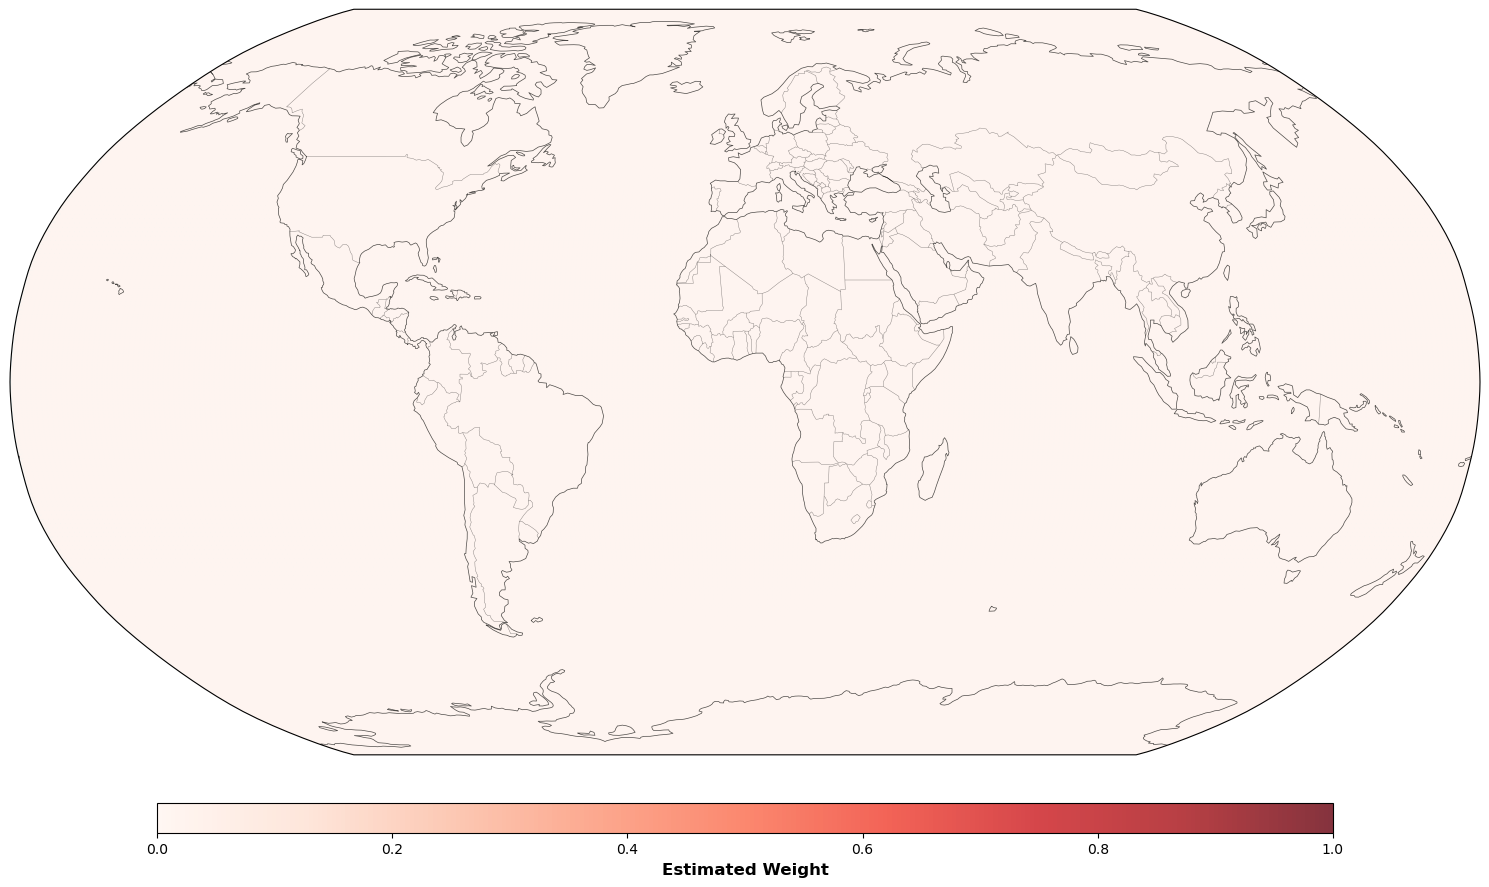

In [8]:
# Cell 2: Create map, plot data, and format
# Create figure with Robinson projection (great for global views)
fig = plt.figure(figsize=(15, 10))
ax = plt.axes(projection=ccrs.Robinson())
# ax = plt.axes(projection=ccrs.Orthographic(central_longitude=0, central_latitude=-90))


# Add map features for aesthetics
ax.add_feature(cfeature.COASTLINE, linewidth=0.5, alpha=0.7)#, color='white')
ax.add_feature(cfeature.BORDERS, linewidth=0.3, alpha=0.5)#, color='white')
ax.add_feature(cfeature.OCEAN, color='lightblue', alpha=0.3)
ax.add_feature(cfeature.LAND, color='lightgray', alpha=0.3)

# Create the scatter plot
scatter = ax.scatter(df_global['Lon'], df_global['Lat'], 
                    c=df_global['Res'], 
                    # cmap='bwr',  # Beautiful colormap
                    # cmap='viridis',  # Colormap for positive values
                    cmap='Reds',  # Colormap for positive values
                    s=30,  # Small point size for dense data
                    alpha=0.8,
                    vmin=0, vmax=1,  # Set color limits for better contrast
                    # vmin=0, vmax=90,  # Set color limits for better contrast
                    # vmin=0, vmax=.6,  # Set color limits for better contrast

                    transform=ccrs.PlateCarree())  # Data is in lat/lon

# knots_scatter = ax.scatter(knots_df['Lon'], knots_df['Lat'],
#                           c='white',          # Color for knot points
#                           s=1,             # Smaller size than main data
#                           marker='x',       # Different marker shape
#                           alpha=0.7,        # Slight transparency
#                           transform=ccrs.PlateCarree(),
#                           label='Knots')

# Add colorbar
cbar = plt.colorbar(scatter, ax=ax, orientation='horizontal', 
                    pad=0.05, shrink=0.8, aspect=40)
cbar.set_label('Estimated Weight', fontsize=12, fontweight='bold')
cbar.ax.tick_params(labelsize=10)

# Add gridlines
# gl = ax.gridlines(draw_labels=False, alpha=0.3, linestyle='--')

# Add title
# plt.title('Global Residual Distribution', fontsize=16, fontweight='bold', pad=20)

# Adjust layout and display
plt.tight_layout()
plt.show()

In [73]:
# Publication Quality Plot: Load and explore dataset1a.csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib import cm
import seaborn as sns

# Set style for publication-quality plots
plt.style.use('default')

# Read the dataset
data = pd.read_csv('data/dataset1a.csv',
                   header=None,
                   names=['value', 'x', 'y', 'value2'])

print(f"Dataset loaded: {len(data):,} points")
print(f"Value range: {data['value'].min():.4f} to {data['value'].max():.4f}")
print(f"X range: {data['x'].min():.4f} to {data['x'].max():.4f}")
print(f"Y range: {data['y'].min():.4f} to {data['y'].max():.4f}")
print(f"Value2 range: {data['value2'].min():.4f} to {data['value2'].max():.4f}")

# Show basic statistics
print(f"\nDataset Statistics:")
print(data.describe())

Dataset loaded: 100,000 points
Value range: -0.4438 to 0.5208
X range: 0.0000 to 1.0000
Y range: 0.0000 to 1.0000
Value2 range: 0.0001 to 1.0001

Dataset Statistics:
               value              x              y         value2
count  100000.000000  100000.000000  100000.000000  100000.000000
mean        0.021742       0.499785       0.498743       0.171968
std         0.088370       0.288681       0.288705       0.162542
min        -0.443765       0.000007       0.000037       0.000100
25%        -0.008111       0.249874       0.248571       0.058160
50%         0.024298       0.499818       0.499108       0.119041
75%         0.061208       0.749680       0.748461       0.230156
max         0.520765       0.999991       0.999995       1.000100


In [206]:
# Cell 1: Import libraries and load global dataset
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import pandas as pd
import numpy as np

# Load the global dataset
df_global = pd.read_csv("~/Documents/nonstat/ncar.csv", header=0, names=['Res', 'Lon', 'Lat'])

print(f"Loaded dataset with {len(df_global):,} points")
print(f"Columns: {list(df_global.columns)}")
print(f"Data preview:")
print(df_global.head())

Loaded dataset with 55,296 points
Columns: ['Res', 'Lon', 'Lat']
Data preview:
        Res      Lon       Lat
0  6.823509 -179.375  89.53125
1  6.815903 -178.125  89.53125
2  6.808998 -176.875  89.53125
3  6.802780 -175.625  89.53125
4  6.797104 -174.375  89.53125


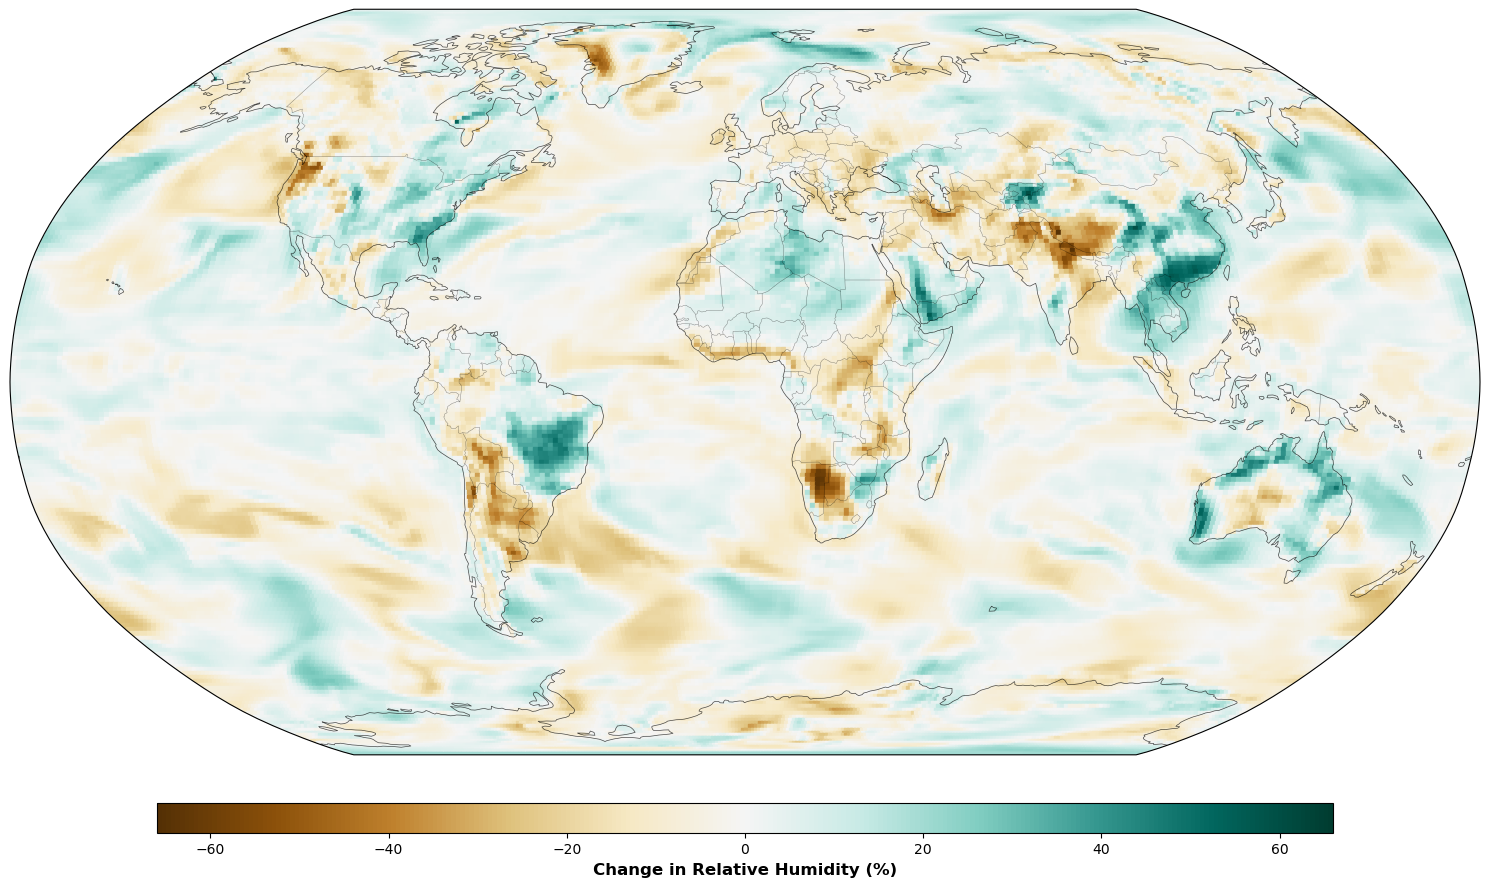

In [223]:
# Cell 2: Create map, plot data, and format
# Create figure with Robinson projection (great for global views)
fig = plt.figure(figsize=(15, 10))
ax = plt.axes(projection=ccrs.Robinson())
# ax = plt.axes(projection=ccrs.Orthographic(central_longitude=0, central_latitude=-90))


# Add map features for aesthetics
ax.add_feature(cfeature.COASTLINE, linewidth=0.5, alpha=0.7)
ax.add_feature(cfeature.BORDERS, linewidth=0.3, alpha=0.5)
ax.add_feature(cfeature.OCEAN, color='lightblue', alpha=0.3)
ax.add_feature(cfeature.LAND, color='lightgray', alpha=0.3)

# Create the scatter plot
scatter = ax.scatter(df_global['Lon'], df_global['Lat'], 
                    c=df_global['Res'], 
                    cmap='BrBG',  # Beautiful colormap
                    # cmap='viridis',  # Colormap for positive values
                    # cmap='Reds',  # Colormap for positive values
                    s=10,  # Small point size for dense data
                    marker='s',
                    alpha=1,
                    vmin=-66, vmax=66,  # Set color limits for better contrast
                    # vmin=0, vmax=1,  # Set color limits for better contrast
                    transform=ccrs.PlateCarree())  # Data is in lat/lon

# Add colorbar
cbar = plt.colorbar(scatter, ax=ax, orientation='horizontal', 
                    pad=0.05, shrink=0.8, aspect=40)
cbar.set_label('Change in Relative Humidity (%)', fontsize=12, fontweight='bold')
cbar.ax.tick_params(labelsize=10)

# Add gridlines
# gl = ax.gridlines(draw_labels=False, alpha=0.3, linestyle='--')

# Add title
# plt.title('Global Residual Distribution', fontsize=16, fontweight='bold', pad=20)

# Adjust layout and display
plt.tight_layout()
plt.show()

In [35]:
# Load and explore the heaton.csv dataset with datashader
import datashader as ds
import datashader.transfer_functions as tf
import pandas as pd
import numpy as np
from colorcet import fire, rainbow, bmy
import matplotlib.pyplot as plt
from datashader.colors import *

# Load the heaton dataset
print("Loading heaton.csv dataset...")
# heaton_data = pd.read_csv('~/Documents/nonstat/heaton_train.csv', header=0, names=['value', 'Lon', 'Lat'])
# heaton_data = pd.read_csv('~/Documents/nonstat/heaton_train.csv', header=0, names=['Lon', 'Lat', 'value', 'Hold'])
# heaton_data = pd.read_csv('~/Documents/NeuralParam/heaton_var_neural.csv', header=0, names=['value', 'Lon', 'Lat'])
# heaton_data = pd.read_csv('~/Documents/NeuralParam/heaton_var_basis.csv', header=0, names=['value', 'Lon', 'Lat'])
heaton_data = pd.read_csv('~/Documents/nonstat/heaton_nu_neural.csv', header=0, names=['value', 'Lon', 'Lat'])
# heaton_data = pd.read_csv('~/Documents/NeuralParam/heaton_nu_basis.csv', header=0, names=['value', 'Lon', 'Lat'])

# heaton_data = pd.read_csv('~/Documents/NeuralParam/heaton_noise_neural.csv', header=0, names=['value', 'Lon', 'Lat'])
# heaton_data = pd.read_csv('~/Documents/NeuralParam/heaton_noise_basis.csv', header=0, names=['value', 'Lon', 'Lat'])

# heaton_data = pd.read_csv('~/Documents/NeuralParam/test.csv', header=0, names=['value', 'Lon', 'Lat'])
# heaton_data = pd.read_csv('~/Documents/nonstat/heaton_nu_basis4.csv', header=0, names=['value', 'Lon', 'Lat'])
# heaton_data = pd.read_csv('~/Documents/nonstat/heaton_noise_basis4.csv', header=0, names=['value', 'Lon', 'Lat'])



# Display basic information about the dataset
# print(f"Dataset shape: {heaton_data.shape}")
# print(f"Columns: {list(heaton_data.columns)}")
# print("\nFirst few rows:")
# print(heaton_data.head())
# print("\nData types:")
# print(heaton_data.dtypes)
# print("\nSummary statistics:")
print(heaton_data.describe())

Loading heaton.csv dataset...
               value            Lon            Lat
count  148308.000000  148308.000000  148308.000000
mean        0.804254     -93.598106      35.682545
std         0.181302       1.330416       0.797414
min         0.166980     -95.911530      34.295192
25%         0.750755     -94.743008      34.990740
50%         0.870979     -93.602307      35.686289
75%         0.931132     -92.452333      36.372563
max         0.997048     -91.283811      37.068111


Longitude range: (-95.9115299916597, -91.2838106505421)
Latitude range: (34.2951918098415, 37.0681113261051)
Value range: (0.17, 1.00)


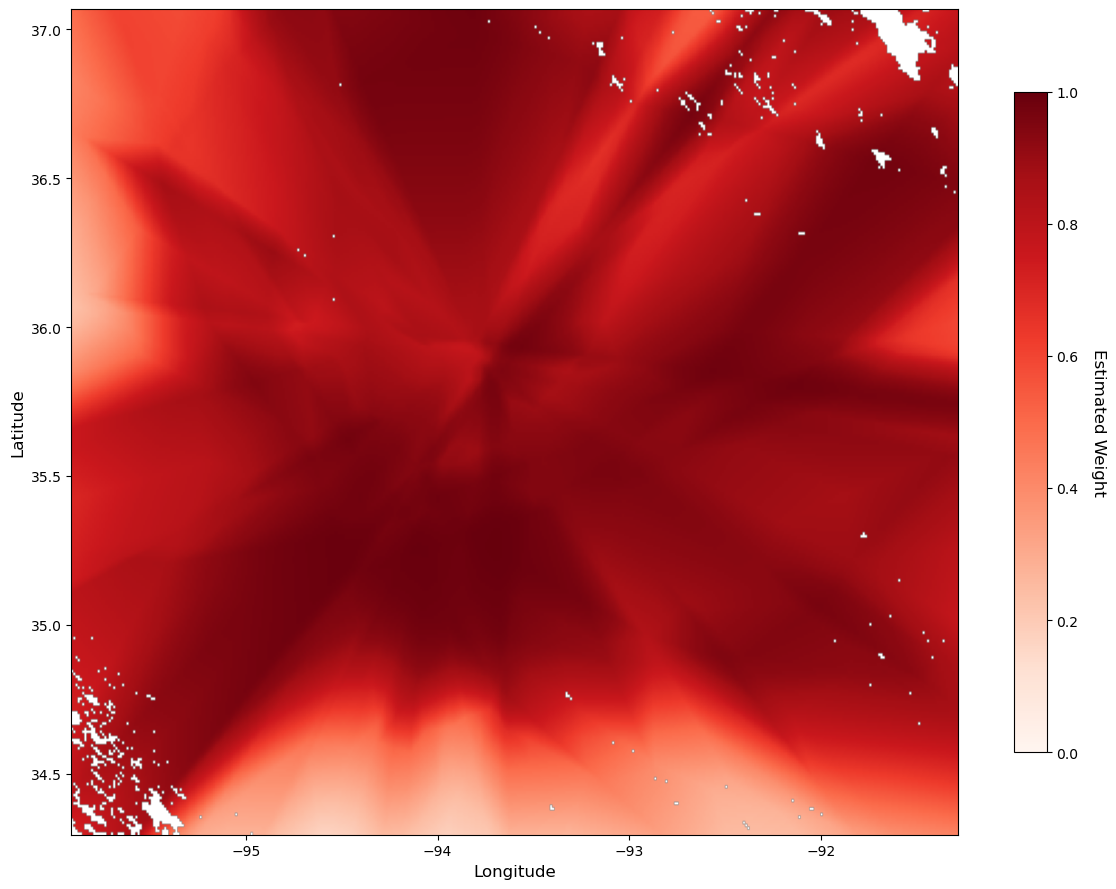

In [36]:
# Create basic datashader visualization
# Clean column names if needed
# if 'df...4.' in heaton_data.columns:
#     heaton_data = heaton_data.rename(columns={'df...4.': 'value'})

# Set up the canvas size and bounds
# Automatically determine bounds from the data
lon_range = (heaton_data['Lon'].min(), heaton_data['Lon'].max())
lat_range = (heaton_data['Lat'].min(), heaton_data['Lat'].max())

print(f"Longitude range: {lon_range}")
print(f"Latitude range: {lat_range}")
print(f"Value range: ({heaton_data['value'].min():.2f}, {heaton_data['value'].max():.2f})")

# Create datashader canvas
canvas = ds.Canvas(plot_width=400, plot_height=300, 
                   x_range=lon_range, y_range=lat_range)

# Aggregate the data using mean reduction for the value column
agg = canvas.points(heaton_data, 'Lon', 'Lat', agg=ds.mean('value'))

# Create the image using a colormap
img = tf.shade(agg, cmap=plt.cm.Reds, how='linear', span=[0, 1])
# img = tf.shade(agg, cmap=plt.cm.Reds, how='linear', span=[0, 14])



# Display the plot
import matplotlib.pyplot as plt
from PIL import Image
import io

# Convert datashader image to matplotlib
fig, ax = plt.subplots(figsize=(12, 9))
ax.imshow(img.to_pil(), extent=[lon_range[0], lon_range[1], lat_range[0], lat_range[1]], 
          aspect='auto', origin='lower')
ax.set_xlabel('Longitude', fontsize=12)
ax.set_ylabel('Latitude', fontsize=12) 
# ax.set_title('Heaton Dataset - Datashader Visualization', fontsize=14, fontweight='bold')

# Add colorbar
# Get the value range from the aggregated data
vmin, vmax = 0, 1
# vmin, vmax = float(agg.min()), float(agg.max())
# vmin, vmax = 24, 56
norm = plt.Normalize(vmin=vmin, vmax=vmax)
sm = plt.cm.ScalarMappable(
    # cmap=plt.cm.viridis, 
    # cmap=plt.cm.RdBu_r,
    cmap = plt.cm.Reds,
    norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, shrink=0.8)
cbar.set_label('Estimated Weight', rotation=270, labelpad=20, fontsize=12)
# cbar.set_label('Standard deviation', rotation=270, labelpad=20, fontsize=12)




plt.tight_layout()
plt.show()

Loading MODIS dataset...
Dataset shape: (33750, 3)
Columns: ['value', 'x', 'y']
Response variable range: 0.0000 to 0.9999
X coordinate range: 1.0 to 225.0
Y coordinate range: 1.0 to 150.0


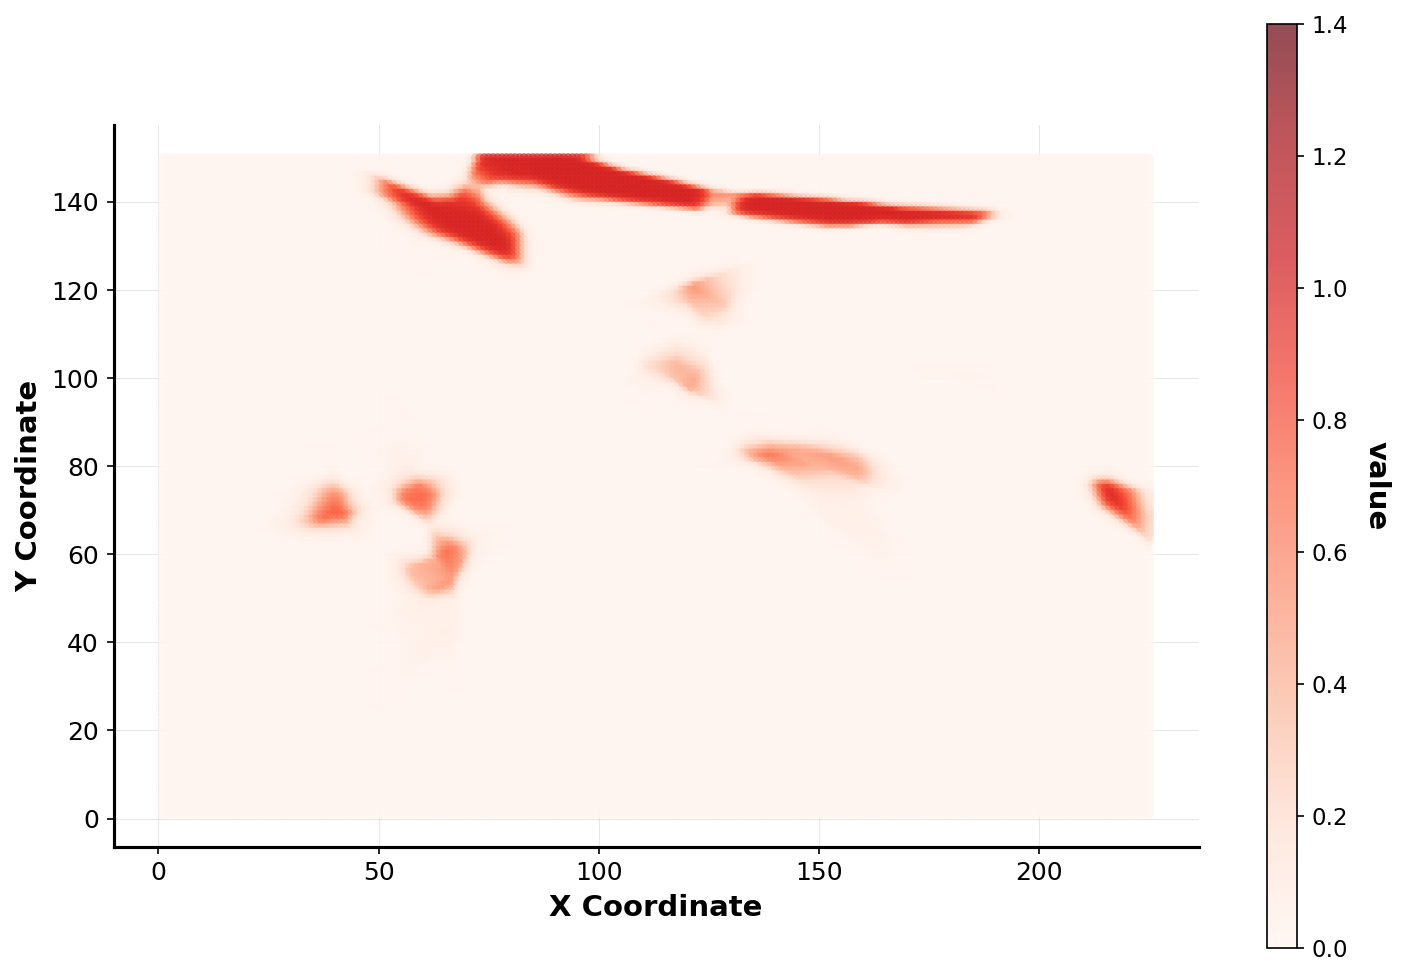


Summary Statistics:
Response variable (value):
  Mean: 0.0400
  Std:  0.1605
  Min:  0.0000
  Max:  0.9999


In [86]:
# Load and plot MODIS data aesthetically
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

# Load MODIS data
print("Loading MODIS dataset...")
modis_data = pd.read_csv('~/Documents/nonstat/modis_neural.csv', header=None, names=['value', 'x', 'y'])

# Display basic information
print(f"Dataset shape: {modis_data.shape}")
print(f"Columns: {list(modis_data.columns)}")
print(f"Response variable range: {modis_data.iloc[:, 0].min():.4f} to {modis_data.iloc[:, 0].max():.4f}")
print(f"X coordinate range: {modis_data.iloc[:, 1].min()} to {modis_data.iloc[:, 1].max()}")
print(f"Y coordinate range: {modis_data.iloc[:, 2].min()} to {modis_data.iloc[:, 2].max()}")

# Create figure with high DPI for crisp display
fig, ax = plt.subplots(figsize=(10, 8), dpi=150)

# Create scatter plot with the first column as response (color) 
# and second/third columns as coordinates
scatter = ax.scatter(modis_data.iloc[:, 1], modis_data.iloc[:, 2], 
                    c=modis_data.iloc[:, 0],
                    s=20,  # Point size
                    alpha=0.7,  # Transparency for overlapping points
                    # cmap='Blues',  # Aesthetic colormap
                    vmin=0, vmax=1.4,  # Set color limits for better contrast
                    cmap='Reds',  # Aesthetic colormap for positive values
                    edgecolors='none',  # Clean appearance
                    rasterized=True)

# Customize the plot for aesthetic appeal
ax.set_xlabel('X Coordinate', fontsize=14, fontweight='bold')
ax.set_ylabel('Y Coordinate', fontsize=14, fontweight='bold')
# ax.set_title('MODIS Data Spatial Distribution', fontsize=16, fontweight='bold', pad=20)

# Set aspect ratio to be equal for proper spatial representation
ax.set_aspect('equal', adjustable='box')

# Customize tick parameters
ax.tick_params(axis='both', which='major', labelsize=12)
ax.grid(True, alpha=0.3, linestyle='-', linewidth=0.5)
ax.set_axisbelow(True)  # Grid behind points

# Add colorbar with proper formatting
cbar = plt.colorbar(scatter, ax=ax, shrink=0.8, aspect=30)
cbar.set_label(modis_data.columns[0], fontsize=14, fontweight='bold', rotation=270, labelpad=20)
cbar.ax.tick_params(labelsize=11)

# Remove top and right spines for cleaner appearance
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)

# Tight layout for better spacing
plt.tight_layout()
plt.show()

# Print summary statistics
print(f"\nSummary Statistics:")
print(f"Response variable ({modis_data.columns[0]}):")
print(f"  Mean: {modis_data.iloc[:, 0].mean():.4f}")
print(f"  Std:  {modis_data.iloc[:, 0].std():.4f}")
print(f"  Min:  {modis_data.iloc[:, 0].min():.4f}")
print(f"  Max:  {modis_data.iloc[:, 0].max():.4f}")

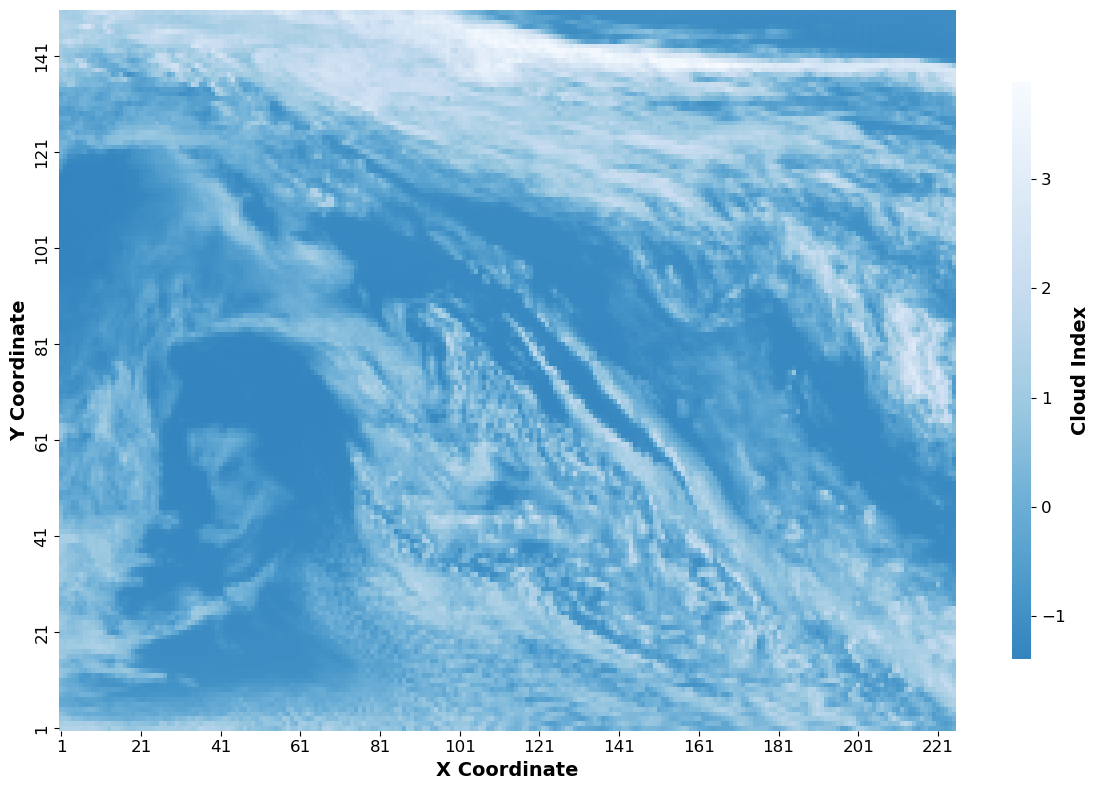

MODIS Data Summary:
Data shape: (33750, 3)
X range: 1 to 225
Y range: 1 to 150
Z range: -1.393 to 3.891
Z mean: -0.000
Z std: 1.000


In [76]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import warnings
warnings.filterwarnings('ignore')

# Set style for publication quality plots
plt.style.use('default')
sns.set_palette("viridis")

# Load the data
df = pd.read_csv('modis.csv')

# Create a pivot table to convert to matrix format for heatmap
data_matrix = df.pivot(index='y', columns='x', values='z_unthresholded')

# Create figure with publication quality settings
fig, ax = plt.subplots(figsize=(12, 8))

# Create the heatmap with improved aesthetics
heatmap = sns.heatmap(data_matrix,
                     cmap='Blues_r',  # Red-Yellow-Blue colormap (reversed)
                     center=0,  # Center colormap at 0
                     cbar_kws={'label': 'Cloud Index',
                              'shrink': 0.8,
                              'aspect': 30},
                     ax=ax,
                     square=False,
                     xticklabels=20,  # Show every 20th x-label
                     yticklabels=20)  # Show every 20th y-label

# Customize the plot for publication quality
# ax.set_title('MODIS Spatial Data Visualization',
#              fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('X Coordinate', fontsize=14, fontweight='bold')
ax.set_ylabel('Y Coordinate', fontsize=14, fontweight='bold')

# Improve tick labels
ax.tick_params(axis='both', which='major', labelsize=12)
ax.invert_yaxis()  # Invert y-axis to match standard geographic convention

# Adjust colorbar
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=12)
cbar.set_label('Cloud Index', fontsize=14, fontweight='bold')

# Tight layout for better spacing
plt.tight_layout()

# Save as high-resolution figure
plt.savefig('modis_publication_plot.png', dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.savefig('modis_publication_plot.pdf', dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')

plt.show()

# Print some basic statistics
print("MODIS Data Summary:")
print(f"Data shape: {df.shape}")
print(f"X range: {df['x'].min()} to {df['x'].max()}")
print(f"Y range: {df['y'].min()} to {df['y'].max()}")
print(f"Z range: {df['z_unthresholded'].min():.3f} to {df['z_unthresholded'].max():.3f}")
print(f"Z mean: {df['z_unthresholded'].mean():.3f}")
print(f"Z std: {df['z_unthresholded'].std():.3f}")